In [1]:
import numpy as np
import plotly.graph_objects as go
import math
import plotly.io as pio
pio.renderers.default = "png"

# Example 9.1 : State Aggregation on the 1000-state Random Walk

In [2]:
def sampleRWTrajectory(policy, nStates=5, leftReward=0, nReachableStates=1):
    currentState = nStates // 2
    stateTrajectory = []
    actionTrajectory = []
    rewardTrajectory = []

    terminal = False
    while not terminal:
        stateTrajectory.append(currentState)
        reward = 0
        currentAction = np.random.choice([-1, 1], p=policy[currentState])
        actionTrajectory.append(currentAction)
        if currentAction == 1:
            nRightStates = nStates - currentState - 1
            pTerminal = 1 - min(nReachableStates, nRightStates) / nReachableStates
            nextState = np.random.choice(min(nReachableStates, nRightStates) + 1, p=[1/nReachableStates] * min(nReachableStates, nRightStates) + [pTerminal]) + currentState + 1
        else:
            nLeftStates = currentState
            pTerminal = 1 - min(nReachableStates, nLeftStates) / nReachableStates
            nextState = np.random.choice(np.arange(max(currentState - nReachableStates, 0), currentState + 1), p=[1/nReachableStates] * min(nReachableStates, nLeftStates) + [pTerminal])
            # nextState = currentState - (np.random.choice(np.arange(-1, (min(nReachableStates, nLeftStates))), p=[pTerminal] + [1/nReachableStates] * min(nReachableStates, nLeftStates)) + 1)

        if nextState == currentState:
            terminal = True
            reward = leftReward
        
        elif nextState == nStates:
            terminal = True
            reward = 1
        
        rewardTrajectory.append(reward)
        currentState = nextState

    trajectory = np.empty((len(stateTrajectory), 3), dtype=int)
    trajectory[:, 0] = stateTrajectory
    trajectory[:, 1] = actionTrajectory
    trajectory[:, 2] = rewardTrajectory

    return trajectory 

The differentiable function to use is simply $\hat{v}:\mathcal{S}\times\mathbb{R}^{10} \mapsto \mathbb{R}$ such that $\hat{v}(s, \mathbf{w}) = \mathbf{w}([s])$, where $[s]$ is the class representative of the group to which $s$ belongs.

In [3]:
def aggregatedSGDMC(policy, wInit, nEpisodes, alpha=2e-5, nStates=1000, leftReward=-1, nReachableStates=100):
    W = wInit.copy()
    mu = np.zeros(nStates)
    groupLength = nStates // len(W)

    for episode in range(nEpisodes):
        trajectory = sampleRWTrajectory(policy, nStates, leftReward, nReachableStates)
        for t in range(len(trajectory)):
            currentState = trajectory[t, 0]
            mu[currentState] += 1
            currentGroup = math.ceil((currentState + 1) / groupLength) - 1
            currentReturn = trajectory[-1, 2]
            W[currentGroup] += alpha * (currentReturn - W[currentGroup])

    return W, mu / np.sum(mu)

In [4]:
def policyEvalRW(nStates, policy, leftReward=-1, nReachableStates=100, theta=1e-4):
    V = np.zeros(nStates)

    converged = False
    t = 0
    while not converged:
        # print("Run", t)
        delta = 0
        for s in range(nReachableStates):
            v = V[s]
            V[s] = policy[s, 0] * (leftReward * (1 - s / nReachableStates) + np.sum(V[:s]) / nReachableStates) + policy[s, 1] * np.sum(V[s+1:s+nReachableStates+1]) / nReachableStates
            delta = max(delta, abs(v - V[s]))

        for s in range(nReachableStates, nStates - nReachableStates):
            v = V[s]
            V[s] = policy[s, 0] * np.sum(V[s-nReachableStates:s]) / nReachableStates + policy[s, 1] * np.sum(V[s+1:s+nReachableStates+1]) / nReachableStates
            delta = max(delta, abs(v - V[s]))

        for s in range(nStates - nReachableStates, nStates):
            v = V[s]
            V[s] = policy[s, 0] * np.sum(V[s-nReachableStates:s]) / nReachableStates + policy[s, 1] * (1 - (nStates - s - 1) / nReachableStates + np.sum(V[s+1:]) / nReachableStates)
            delta = max(delta, abs(v - V[s]))

        converged = delta < theta
        t += 1

    return V

In [5]:
nStatesRW = 1000
nGroupsRW = 10
nReachableStatesRW = 100
policyRW = 0.5 * np.ones((nStatesRW, 2))
trueValue = policyEvalRW(nStatesRW, policyRW, nReachableStates=nReachableStatesRW, leftReward=-1)

In [6]:
wInitRW = np.zeros(nGroupsRW)
nEpisodesRW = 100000
wAggregatedSGDMC, muAggregatedSGDMC = aggregatedSGDMC(policyRW, wInitRW, nEpisodesRW, nStates=nStatesRW, leftReward=-1)

In [7]:
vAggregatedSGDMC = np.repeat(wAggregatedSGDMC, nStatesRW // nGroupsRW)

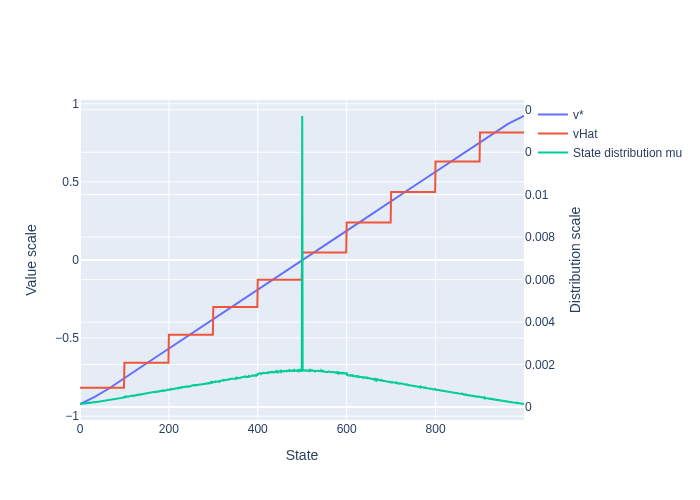

In [8]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=trueValue, name="v*", yaxis="y1"))
fig.add_trace(go.Scatter(y=vAggregatedSGDMC, name="vHat", yaxis="y1"))
fig.add_trace(go.Scatter(y=muAggregatedSGDMC, name="State distribution mu", yaxis="y2"))
fig.update_layout(yaxis2=dict(side="right", overlaying="y"), xaxis_title="State", yaxis_title="Value scale", yaxis2_title="Distribution scale", width=700)

# Example 9.2 : Bootstrapping on the 1000-state Random Walk

In [9]:
def aggregatedSGDBootstrap(policy, wInit, nEpisodes, nStep, alpha=2e-5, nStates=1000, leftReward=-1, nReachableStates=100, trueValue=None):
    W = wInit.copy()
    groupLength = nStates // len(W)

    if trueValue is not None:
        learningCurve = np.empty((nEpisodes, nStates))

    for episode in range(nEpisodes):
        currentState = nStates // 2
        stateTrajectory = [currentState]
    
        T = np.inf
        t = 0
        tau = t - nStep + 1
        reward = 0
        while tau < T - 1:
            if t < T:
                currentAction = np.random.choice([-1, 1], p=policy[currentState])
                if currentAction == 1:
                    nRightStates = nStates - currentState - 1
                    pTerminal = 1 - min(nReachableStates, nRightStates) / nReachableStates
                    nextState = np.random.choice(min(nReachableStates, nRightStates) + 1, p=[1/nReachableStates] * min(nReachableStates, nRightStates) + [pTerminal]) + currentState + 1
                else:
                    nLeftStates = currentState
                    pTerminal = 1 - min(nReachableStates, nLeftStates) / nReachableStates
                    nextState = np.random.choice(np.arange(max(currentState - nReachableStates, 0), currentState + 1), p=[1/nReachableStates] * min(nReachableStates, nLeftStates) + [pTerminal])

                if nextState == currentState:
                    reward = leftReward
                    T = t + 1
                
                elif nextState == nStates:
                    reward = 1
                    T = t + 1

                else:
                    currentState = nextState
                    stateTrajectory.append(nextState)

            tau = t - nStep + 1
            if tau >= 0:
                stateTau = stateTrajectory[tau]
                if tau + nStep < T:
                    update = W[math.ceil((stateTrajectory[tau+nStep] + 1) / groupLength) - 1]
                else:
                    update = reward
                update -= W[math.ceil((stateTau + 1) / groupLength) - 1]
                update *= alpha
                W[math.ceil((stateTau + 1) / groupLength) - 1] += update

            t += 1
            
        if trueValue is not None:
            learningCurve[episode] = np.repeat(W, groupLength)

    if trueValue is not None:
        return np.mean(np.sqrt(np.mean((learningCurve - trueValue) ** 2, axis=1)))

    return W

In [10]:
# def aggregatedSGDBootstrap(policy, wInit, nEpisodes, nStep, alpha=2e-5, nStates=1000, leftReward=-1, nReachableStates=100, trajectories=None, trueValue=None):
#     W = wInit.copy()
#     groupLength = nStates // len(W)

#     if trueValue is not None:
#         learningCurve = np.empty((nEpisodes, nStates))

#     for episode in range(nEpisodes):
#         if trajectories is None:
#             trajectory = sampleRWTrajectory(policy, nStates, leftReward, nReachableStates)
#         else:
#             trajectory = trajectories[episode]
#         for t in range(len(trajectory)):
#             currentState = trajectory[t, 0]
#             currentGroup = math.ceil((currentState + 1) / groupLength) - 1
#             # currentReward = np.sum(trajectory[t:t+nStep, 2])
#             if t + nStep < len(trajectory):
#                 nextState = trajectory[t+nStep, 0]
#                 nextGroup = math.ceil((nextState + 1) / groupLength) - 1
#                 nextStateW = W[nextGroup]
#                 currentReward = 0
#             else:
#                 nextStateW = 0
#                 currentReward = trajectory[-1, 2]
                
#             W[currentGroup] += alpha * (currentReward + nextStateW - W[currentGroup])

#         if trueValue is not None:
#             learningCurve[episode] = np.repeat(W, groupLength)

#     if trueValue is not None:
#         return np.mean(np.sqrt(np.mean((learningCurve - trueValue) ** 2, axis=1)))

#     return W

In [11]:
nStepRW = 1
wAggregatedSGDBootstrap = aggregatedSGDBootstrap(policyRW, wInitRW, nEpisodesRW, nStates=nStatesRW, nStep=nStepRW, leftReward=-1, alpha=1e-4)

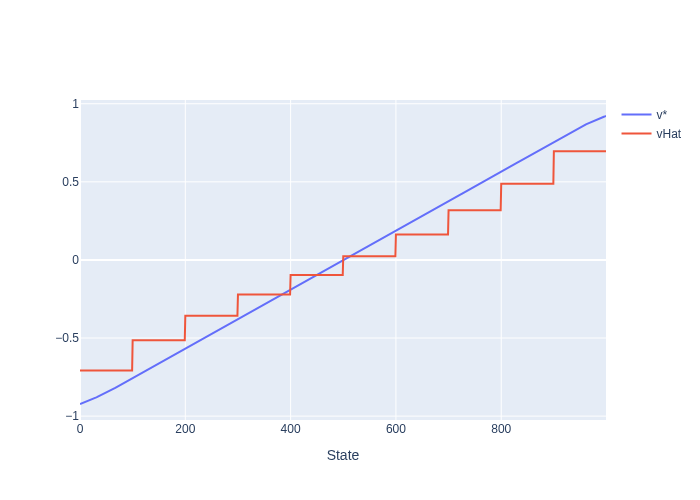

In [12]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=trueValue, name="v*", yaxis="y1"))
fig.add_trace(go.Scatter(y=np.repeat(wAggregatedSGDBootstrap, nStatesRW // nGroupsRW), name="vHat", yaxis="y1"))
fig.update_layout(width=700, xaxis_title="State")

In [13]:
def prepareExperimentsBootstrap(wInit, policy, nStates, leftReward, trueValue, nEpisodes, nReps, nList, alphas, nReachableStates=100):
    errors = {}
    for n in nList:
        print("n", n)
        nErrors = []
        for alpha in alphas[n]:
            nAlphaErrors = []
            for rep in range(nReps):
                nAlphaErrors.append(aggregatedSGDBootstrap(policy, wInit, nEpisodes, n, alpha=alpha, nStates=nStates, leftReward=leftReward, nReachableStates=nReachableStates, trueValue=trueValue))
            nErrors.append(np.mean(nAlphaErrors))
        errors[n] = nErrors

    return errors

In [15]:
nGroupsRWBootstrap = 20
wInitRWBootstrap = np.zeros(nGroupsRWBootstrap)
leftReward = -1
nEpisodes = 10
nReps = 100
nList = 2 ** np.arange(8)
alphas = {1: np.linspace(0.01, 1, 50), 2: np.linspace(0.01, 1, 50), 4: np.linspace(0.01, 1, 50), 8: np.linspace(0.01, 0.9, 50), 16: np.linspace(0.01, 0.7, 50),
          32: np.linspace(0.01, 0.4, 50), 64: np.linspace(0.01, 0.2, 50), 128: np.linspace(0.01, 0.1, 50)}
nCurves = prepareExperimentsBootstrap(wInitRWBootstrap, policyRW, nStatesRW, leftReward, trueValue, nEpisodes, nReps, nList, alphas, nReachableStatesRW)

n 1
n 2
n 4
n 8
n 16
n 32
n 64
n 128


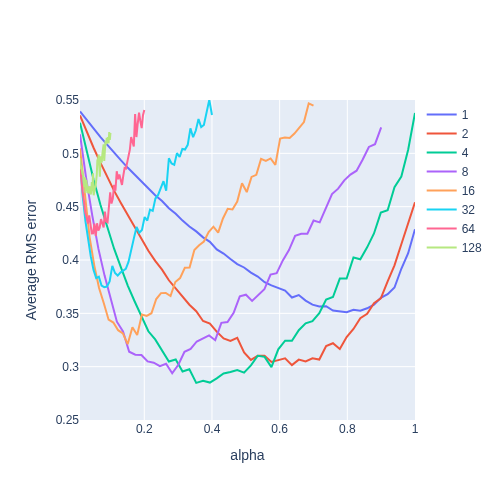

In [16]:
fig = go.Figure()
for n in nList:
    fig.add_trace(go.Scatter(x=alphas[n], y=nCurves[n], name=str(n)))
fig.update_layout(width=500, xaxis_title="alpha", yaxis_title="Average RMS error")
fig.update_yaxes(range=[0.25, 0.55])
fig.show()

# Feature Construction for Linear Models

In the polynomial base case, $\mathbf{x}(s) = (1, s, s^2, s^3, s^4, s^5)$  
In the Fourier basis case, $\mathbf{x}(s) = (1, \cos (\pi s), \cos (2 \pi s), \cos (3 \pi s), \cos (4 \pi s), \cos (5 \pi s))$

In [17]:
def linearSGDMC(policy, wInit, nEpisodes, alpha=2e-5, nStates=1000, leftReward=-1, nReachableStates=100, trajectories=None, trueValue=None, mu=None, method="poly"):
    W = wInit.copy()

    features = np.arange(len(W))
    states = np.arange(nStates)
    if trueValue is not None:
        learningCurve = np.empty((nEpisodes, nStates))
        error = np.empty(nEpisodes)

    for episode in range(nEpisodes):
        if trajectories is None:
            trajectory = sampleRWTrajectory(policy, nStates, leftReward, nReachableStates)
        else:
            trajectory = trajectories[episode]

        for t in range(len(trajectory)):
            currentState = trajectory[t, 0]
            currentReturn = np.sum(trajectory[t:, 2])
            if method == "poly":
                xFeatures = (currentState / nStates) ** features 
            elif method == "Fourier":
                xFeatures = np.cos(np.pi * currentState * features / nStates)
            W += alpha * (currentReturn - np.sum(W * xFeatures)) * xFeatures

        if trueValue is not None:
            if method == "poly":
                learningCurve[episode] = ((states[:, None] / nStates) ** features) @ W
            else:
                learningCurve[episode] = np.cos(np.pi * states[:, None] * features / nStates) @ W
            error[episode] = np.sqrt(mu @ ((learningCurve[episode] - trueValue) ** 2))
    

    if trueValue is not None:
        return error

    return W

In [18]:
nFeaturesList = [6, 11, 21]
alphaFourier = 5e-5
alphaPoly = 1e-4
nReps = 10
nEpisodes = 5000

avgMrseVEFourier = {}
avgMrseVEPoly = {}
trajectories = []
for rep in range(nReps):
    repTrajectories = []
    for episode in range(nEpisodes):
        repTrajectories.append(sampleRWTrajectory(policyRW, nStates=nStatesRW, leftReward=-1, nReachableStates=100))
    trajectories.append(repTrajectories)

for nFeatures in nFeaturesList:
    mrseVEFourier = []
    mrseVEPoly = []
    wInit = np.zeros(nFeatures)
    for rep in range(nReps):
        mrseVEFourier.append(linearSGDMC(policyRW, wInit, nEpisodes, alphaFourier, nStatesRW, -1, 100, trajectories=trajectories[rep], trueValue=trueValue, mu=muAggregatedSGDMC, method="Fourier"))
        mrseVEPoly.append(linearSGDMC(policyRW, wInit, nEpisodes, alphaPoly, nStatesRW, -1, 100, trajectories=trajectories[rep], trueValue=trueValue, mu=muAggregatedSGDMC, method="poly"))

    avgMrseVEFourier[nFeatures] = np.mean(mrseVEFourier, axis=0)
    avgMrseVEPoly[nFeatures] = np.mean(mrseVEPoly, axis=0)

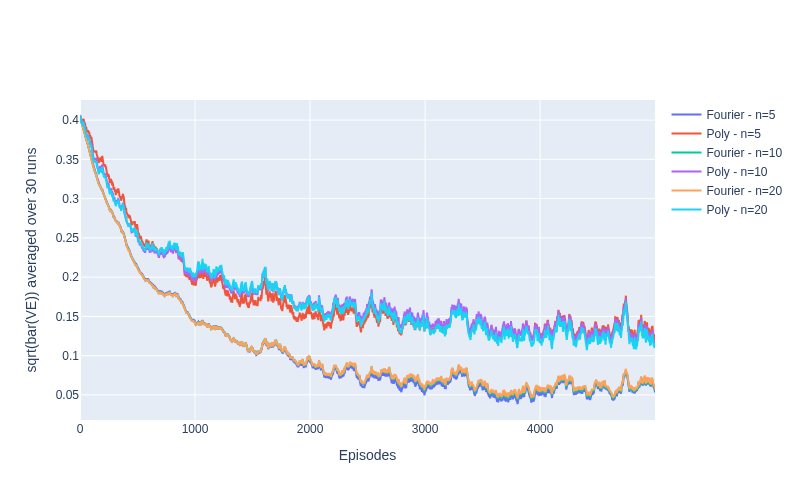

In [19]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=avgMrseVEFourier[6], name="Fourier - n=5"))
fig.add_trace(go.Scatter(y=avgMrseVEPoly[6], name="Poly - n=5"))
fig.add_trace(go.Scatter(y=avgMrseVEFourier[11], name="Fourier - n=10"))
fig.add_trace(go.Scatter(y=avgMrseVEPoly[11], name="Poly - n=10"))
fig.add_trace(go.Scatter(y=avgMrseVEFourier[21], name="Fourier - n=20"))
fig.add_trace(go.Scatter(y=avgMrseVEPoly[21], name="Poly - n=20"))
fig.update_layout(xaxis_title="Episodes", yaxis_title="sqrt(bar(VE)) averaged over 30 runs", width=800)

# Tile Coding

In [20]:
def tileCodingRWMC(policy, wInit, nEpisodes, alpha=2e-5, nStates=1000, leftReward=-1, nReachableStates=100, trajectories=None, trueValue=None, mu=None):
    W = wInit.copy()
    nTilings,  nGroups = W.shape
    groupLength = nStates // (nGroups - 1)
    offset = groupLength // nTilings
    if trueValue is not None:
        learningCurve = np.empty((nEpisodes, nStates))
        error = np.empty(nEpisodes)
        states = np.arange(nStates)[:, None]
        tilings = np.arange(nTilings)
        idx = np.ceil((states + 1 - offset * tilings[None, :]) / groupLength).astype(int)

    for episode in range(nEpisodes):
        if trajectories is None:
            trajectory = sampleRWTrajectory(policy, nStates, leftReward, nReachableStates)
        else:
            trajectory = trajectories[episode]
        for t in range(len(trajectory)):
            currentState = trajectory[t, 0]
            currentReturn = np.sum(trajectory[t:, 2])
            currentVHat = np.sum(W[tilings, idx[currentState]])
            for tiling in range(nTilings):
                currentTile = math.ceil((currentState + 1 - offset * tiling) / groupLength)
                W[tiling][currentTile] += alpha * (currentReturn - currentVHat)

        if trueValue is not None:
            learningCurve[episode] = W[tilings, idx].sum(axis=1)
            error[episode] = np.sqrt(mu @ ((learningCurve[episode] - trueValue) ** 2))
    
    if trueValue is not None:
        return error

    return W

In [21]:
nReps = 30
wInitTC1 = np.zeros((1, 6))
wInitTC50 = np.zeros((50, 6))
nEpisodesTC = 5000
errorTC1Tiling = []
errorTC50Tiling = []

trajectories = []
for rep in range(nReps):
    repTrajectories = []
    for episode in range(nEpisodes):
        repTrajectories.append(sampleRWTrajectory(policyRW, nStates=nStatesRW, leftReward=-1, nReachableStates=100))
    trajectories.append(repTrajectories)

for rep in range(nReps):
    errorTC1Tiling.append(tileCodingRWMC(policyRW, wInitTC1, nEpisodesTC, alpha=1e-4, trajectories=trajectories[rep], trueValue=trueValue, mu=muAggregatedSGDMC))
    errorTC50Tiling.append(tileCodingRWMC(policyRW, wInitTC50, nEpisodesTC, alpha=1e-4/50, trajectories=trajectories[rep], trueValue=trueValue, mu=muAggregatedSGDMC))

avgErrorTC1Tiling = np.mean(errorTC1Tiling, axis=0)
avgErrorTC50Tiling = np.mean(errorTC50Tiling, axis=0)

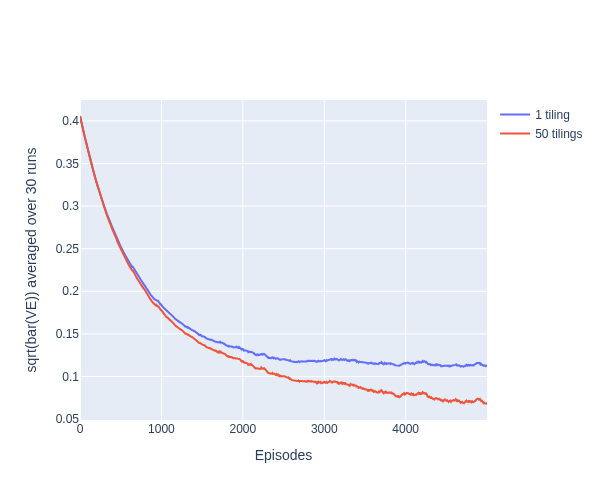

In [22]:
fig = go.Figure()
fig.add_trace(go.Scatter(y=avgErrorTC1Tiling, name="1 tiling"))
fig.add_trace(go.Scatter(y=avgErrorTC50Tiling, name="50 tilings"))
fig.update_layout(xaxis_title="Episodes", yaxis_title="sqrt(bar(VE)) averaged over 30 runs", width=600)

# Exercise 9.5 : Step-Size parameter selection

We would like to have $\alpha = \left (\tau \mathbb{E}[\mathbf{x}^T\mathbf{x}] \right)^{-1}$.  
For each $s \in \mathcal{S}$, there are exactly 98 tiles containing $s$, so that 
\begin{align}
\mathbb{E}[\mathbf{x}^T\mathbf{x}] &= \mathbb{E}[\sum_i \mathbf{x}^2_i[S]]\\
&= \mathbb{E} [\sum_i \mathbf{x}_i[S]] \quad \quad \text{(since } \mathbf{x}_i \in \{0, 1\}) \\
&= \sum_s \mu (s) \sum_i \mathbf{x}_i[s] \\
&= \sum \mu(s) \times 98\\
&= 98
\end{align}

Finally, a suitable $\alpha$ when $\tau = 10$ would then be $1/980$.